In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import plotly.express as px

In [3]:
df = pd.read_csv('owid-co2-data.csv', header=0)

df.head()

,country,year,iso_code,population,gdp,cement_co2,cement_co2_per_capita,co2,co2_growth_abs,co2_growth_prct,...,share_global_other_co2,share_of_temperature_change_from_ghg,temperature_change_from_ch4,temperature_change_from_co2,temperature_change_from_ghg,temperature_change_from_n2o,total_ghg,total_ghg_excluding_lucf,trade_co2,trade_co2_share
0,Afghanistan,1750,AFG,2802560.0,NaN,0.0,0.0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Afghanistan,1751,AFG,NaN,NaN,0.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Afghanistan,1752,AFG,NaN,NaN,0.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Afghanistan,1753,AFG,NaN,NaN,0.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Afghanistan,1754,AFG,NaN,NaN,0.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


# Norway

Exploring co2-data for Norway

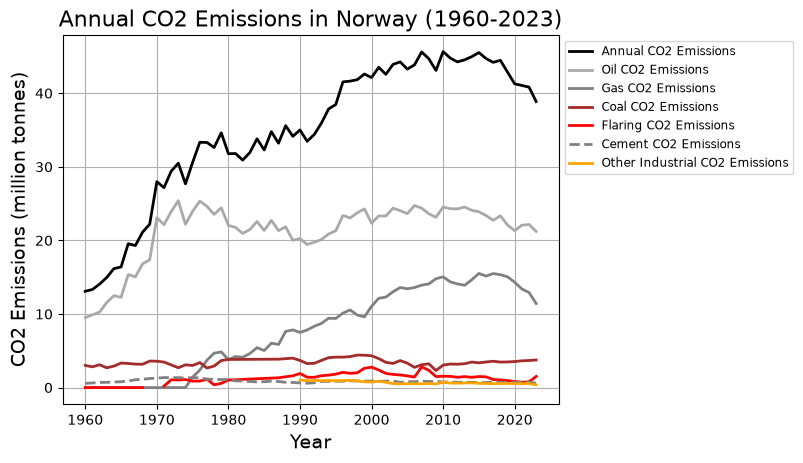

In [4]:
norway = df[df['country'] == 'Norway']
norway_years = norway['year']

annual_co2_emissions = norway['co2']
cement_co2 = norway['cement_co2']
gas_co2 = norway['gas_co2']
flaring_co2 = norway['flaring_co2']
coal_co2 = norway['coal_co2']
oil_co2 = norway['oil_co2']
other_industrial_co2 = norway['other_industry_co2']

plt.Figure(figsize=(10, 6))

plt.plot(norway_years[210:-1], annual_co2_emissions[210:-1], color='black', linestyle='-', linewidth=2, label = 'Annual CO2 Emissions')
plt.plot(norway_years[210:-1], oil_co2[210:-1], color='darkgrey', linestyle='-', linewidth=2, label = 'Oil CO2 Emissions')
plt.plot(norway_years[210:-1], gas_co2[210:-1], color='grey', linestyle='-', linewidth=2, label = 'Gas CO2 Emissions')
plt.plot(norway_years[210:-1], coal_co2[210:-1], color='brown', linestyle='-', linewidth=2, label = 'Coal CO2 Emissions')
plt.plot(norway_years[210:-1], flaring_co2[210:-1], color='red', linestyle='-', linewidth=2, label = 'Flaring CO2 Emissions')
plt.plot(norway_years[210:-1], cement_co2[210:-1], color='gray', linestyle='--', linewidth=2, label = 'Cement CO2 Emissions')
plt.plot(norway_years[210:-1], other_industrial_co2[210:-1], color='orange', linestyle='-', linewidth=2, label = 'Other Industrial CO2 Emissions')

plt.title('Annual CO2 Emissions in Norway (1960-2023)', fontsize=16)
plt.xlabel('Year', fontsize=14)
plt.ylabel('CO2 Emissions (million tonnes)', fontsize=14)
plt.grid(True)
plt.legend(fontsize='small', loc='upper left', bbox_to_anchor=(1, 1))

In [5]:
order = ['coal', 'oil', 'gas', 'other industry', 'cement', 'flaring']

fig = px.area(
    norway.iloc[150:-1],
    x='year',
    y=[
        'coal_co2',
        'oil_co2',
        'gas_co2',
        'other_industry_co2',
        'cement_co2',
        'flaring_co2'
    ],
    title='CO2 Emissions by Source in Norway',
    labels={
        'value': 'CO2 Emission (tonn)',
        'variable': 'Source',
        'year': 'Year'
    },
    color_discrete_map={
        'coal_co2': "#6D6868",
        'oil_co2': '#8C564B',
        'gas_co2': "#FF9500",
        'other_industry_co2': "#6DC86D",
        'cement_co2': "#BC9753",
        'flaring_co2': '#E45756'
    }
)

fig.for_each_trace(lambda t: t.update(
    name=t.name.replace('_co2', '').replace('_', ' ').capitalize()
))

# Reverser legend-rekkefølgen visuelt
fig.update_layout(
    legend=dict(
        traceorder='reversed'
    )
)

fig.show()

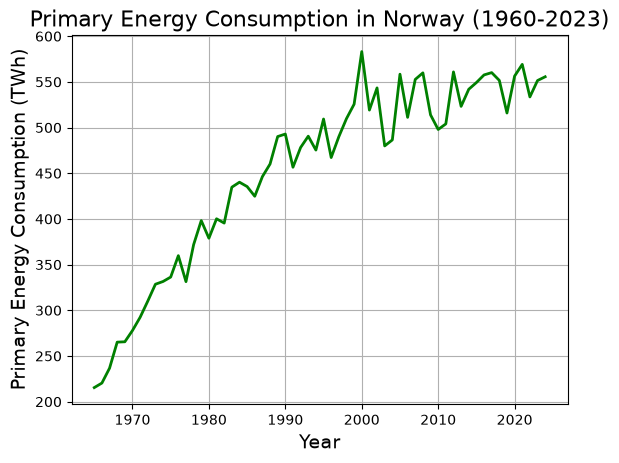

In [6]:
norway_primary_energy_consumption = norway['primary_energy_consumption']

plt.Figure(figsize=(10, 6))
plt.plot(norway_years, norway_primary_energy_consumption, color='green', linestyle='-', linewidth=2, markersize=6)
plt.title('Primary Energy Consumption in Norway (1960-2023)', fontsize=16)
plt.xlabel('Year', fontsize=14)
plt.ylabel('Primary Energy Consumption (TWh)', fontsize=14)
plt.grid(True)

## Greenhouse gas (GHG) emission 

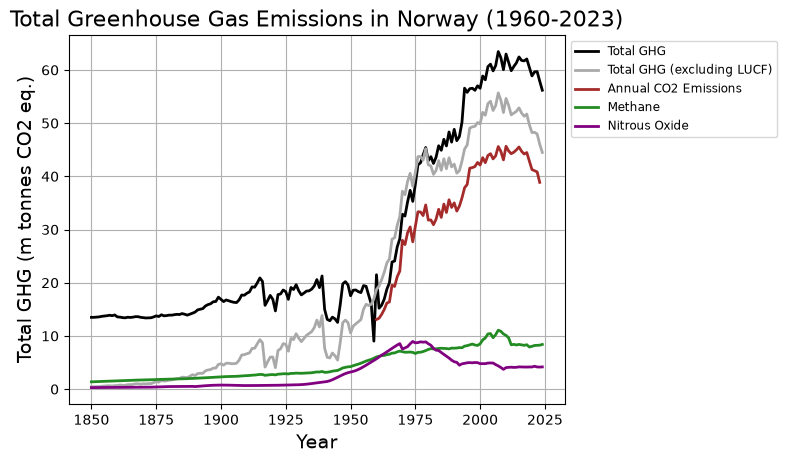

In [7]:
ghg_total = norway['total_ghg']
total_ghg_excluding_lucf = norway['total_ghg_excluding_lucf']
methane = norway['methane']
nitrous_oxide = norway['nitrous_oxide']

plt.Figure(figsize=(10, 6))
plt.plot(norway_years, ghg_total, color='black', linestyle='-', linewidth=2, markersize=6, label='Total GHG')
plt.plot(norway_years, total_ghg_excluding_lucf, color='darkgrey', linestyle='-', linewidth=2, markersize=6, label='Total GHG (excluding LUCF)')
plt.plot(norway_years[210:-1], annual_co2_emissions[210:-1], color='brown', linestyle='-', linewidth=2, label = 'Annual CO2 Emissions')
plt.plot(norway_years, methane, color='forestgreen', linestyle='-', linewidth=2, markersize=6, label='Methane')
plt.plot(norway_years, nitrous_oxide, color='purple', linestyle='-', linewidth=2, markersize=6, label='Nitrous Oxide')
plt.title('Total Greenhouse Gas Emissions in Norway (1960-2023)', fontsize=16)
plt.xlabel('Year', fontsize=14)
plt.ylabel('Total GHG (m tonnes CO2 eq.)', fontsize=14)
plt.grid(True) 
plt.legend(fontsize='small', loc='upper left', bbox_to_anchor=(1, 1))

## Per capita CO2 and GHG-emissions

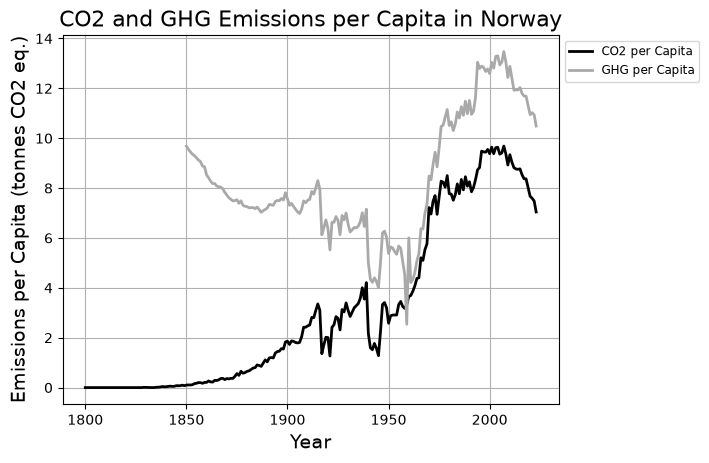

In [8]:
co2_per_capita = norway['co2_per_capita']
ghg_per_capita = norway['ghg_per_capita']

plt.Figure(figsize=(10, 6))
plt.plot(norway_years[50:-1], co2_per_capita[50:-1], color='black', linestyle='-', linewidth=2, markersize=6, label='CO2 per Capita')
plt.plot(norway_years[50:-1], ghg_per_capita[50:-1], color='darkgrey', linestyle='-', linewidth=2, markersize=6, label='GHG per Capita')
plt.title('CO2 and GHG Emissions per Capita in Norway', fontsize=16)
plt.xlabel('Year', fontsize=14)
plt.ylabel('Emissions per Capita (tonnes CO2 eq.)', fontsize=14)
plt.grid(True)
plt.legend(fontsize='small', loc='upper left', bbox_to_anchor=(1, 1))

# Sweden 

Exploring the CO2-data for Sweden.

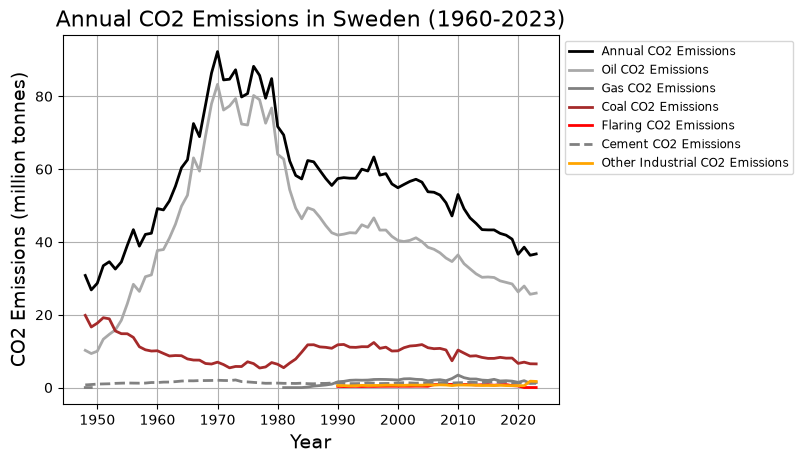

In [9]:
sweden = df[df['country'] == 'Sweden']
sweden_years = sweden['year']

annual_co2_emissions = sweden['co2']
cement_co2 = sweden['cement_co2']
gas_co2 = sweden['gas_co2']
flaring_co2 = sweden['flaring_co2']
coal_co2 = sweden['coal_co2']
oil_co2 = sweden['oil_co2']
other_industrial_co2 = sweden['other_industry_co2']

plt.Figure(figsize=(10, 6))

plt.plot(sweden_years[110:-1], annual_co2_emissions[110:-1], color='black', linestyle='-', linewidth=2, label = 'Annual CO2 Emissions')
plt.plot(sweden_years[110:-1], oil_co2[110:-1], color='darkgrey', linestyle='-', linewidth=2, label = 'Oil CO2 Emissions')
plt.plot(sweden_years[110:-1], gas_co2[110:-1], color='grey', linestyle='-', linewidth=2, label = 'Gas CO2 Emissions')
plt.plot(sweden_years[110:-1], coal_co2[110:-1], color='brown', linestyle='-', linewidth=2, label = 'Coal CO2 Emissions')
plt.plot(sweden_years[110:-1], flaring_co2[110:-1], color='red', linestyle='-', linewidth=2, label = 'Flaring CO2 Emissions')
plt.plot(sweden_years[110:-1], cement_co2[110:-1], color='gray', linestyle='--', linewidth=2, label = 'Cement CO2 Emissions')
plt.plot(sweden_years[110:-1], other_industrial_co2[110:-1], color='orange', linestyle='-', linewidth=2, label = 'Other Industrial CO2 Emissions')

plt.title('Annual CO2 Emissions in Sweden (1960-2023)', fontsize=16)
plt.xlabel('Year', fontsize=14)
plt.ylabel('CO2 Emissions (million tonnes)', fontsize=14)
plt.grid(True)
plt.legend(fontsize='small', loc='upper left', bbox_to_anchor=(1, 1))

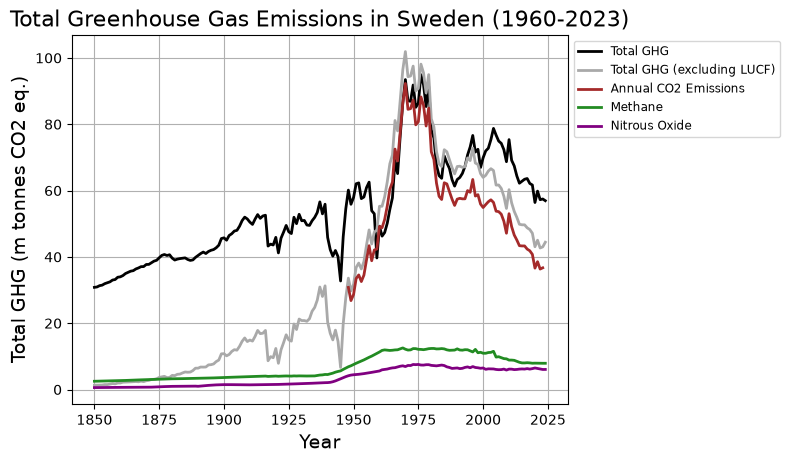

In [10]:
ghg_total = sweden['total_ghg']
total_ghg_excluding_lucf = sweden['total_ghg_excluding_lucf']
methane = sweden['methane']
nitrous_oxide = sweden['nitrous_oxide']

plt.Figure(figsize=(10, 6))
plt.plot(sweden_years, ghg_total, color='black', linestyle='-', linewidth=2, markersize=6, label='Total GHG')
plt.plot(sweden_years, total_ghg_excluding_lucf, color='darkgrey', linestyle='-', linewidth=2, markersize=6, label='Total GHG (excluding LUCF)')
plt.plot(sweden_years[110:-1], annual_co2_emissions[110:-1], color='brown', linestyle='-', linewidth=2, label = 'Annual CO2 Emissions')
plt.plot(sweden_years, methane, color='forestgreen', linestyle='-', linewidth=2, markersize=6, label='Methane')
plt.plot(sweden_years, nitrous_oxide, color='purple', linestyle='-', linewidth=2, markersize=6, label='Nitrous Oxide')
plt.title('Total Greenhouse Gas Emissions in Sweden (1960-2023)', fontsize=16)
plt.xlabel('Year', fontsize=14)
plt.ylabel('Total GHG (m tonnes CO2 eq.)', fontsize=14)
plt.grid(True) 
plt.legend(fontsize='small', loc='upper left', bbox_to_anchor=(1, 1))

## Per capita emissions

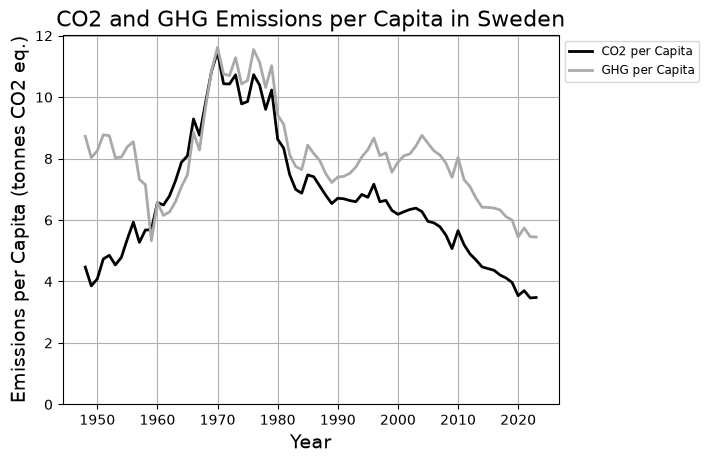

In [11]:
co2_per_capita = sweden['co2_per_capita']
ghg_per_capita = sweden['ghg_per_capita']

plt.Figure(figsize=(10, 6))

plt.plot(sweden_years[110:-1], co2_per_capita[110:-1], color='black', linestyle='-', linewidth=2, markersize=6, label='CO2 per Capita')
plt.plot(sweden_years[110:-1], ghg_per_capita[110:-1], color='darkgrey', linestyle='-', linewidth=2, markersize=6, label='GHG per Capita')

plt.title('CO2 and GHG Emissions per Capita in Sweden', fontsize=16)
plt.xlabel('Year', fontsize=14)
plt.ylabel('Emissions per Capita (tonnes CO2 eq.)', fontsize=14)
plt.ylim(bottom=0)  
plt.grid(True)
plt.legend(fontsize='small', loc='upper left', bbox_to_anchor=(1, 1))

# United Kingdom

In [12]:
united_kingdom = df[df['country'] == 'United Kingdom']
uk_years = united_kingdom['year']

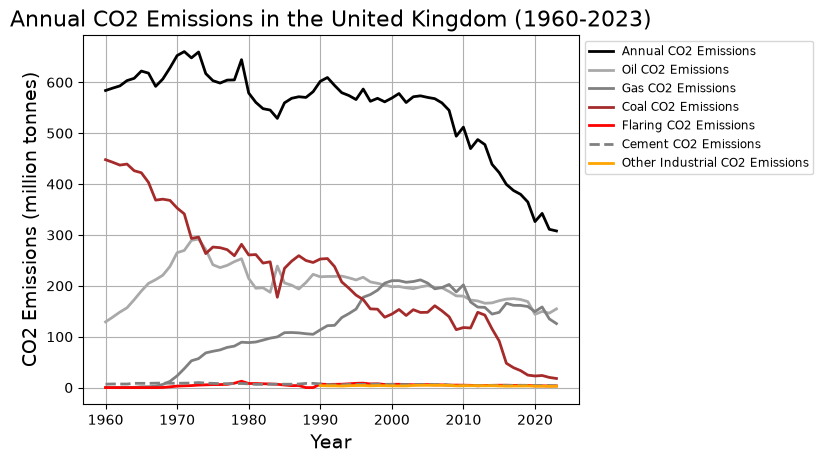

In [13]:
annual_co2_emissions = united_kingdom['co2']
cement_co2 = united_kingdom['cement_co2']
gas_co2 = united_kingdom['gas_co2']
flaring_co2 = united_kingdom['flaring_co2']
coal_co2 = united_kingdom['coal_co2']
oil_co2 = united_kingdom['oil_co2']
other_industrial_co2 = united_kingdom['other_industry_co2']

plt.Figure(figsize=(10, 6))

plt.plot(uk_years[210:-1], annual_co2_emissions[210:-1], color='black', linestyle='-', linewidth=2, label = 'Annual CO2 Emissions')
plt.plot(uk_years[210:-1], oil_co2[210:-1], color='darkgrey', linestyle='-', linewidth=2, label = 'Oil CO2 Emissions')
plt.plot(uk_years[210:-1], gas_co2[210:-1], color='grey', linestyle='-', linewidth=2, label = 'Gas CO2 Emissions')
plt.plot(uk_years[210:-1], coal_co2[210:-1], color='brown', linestyle='-', linewidth=2, label = 'Coal CO2 Emissions')
plt.plot(uk_years[210:-1], flaring_co2[210:-1], color='red', linestyle='-', linewidth=2, label = 'Flaring CO2 Emissions')
plt.plot(uk_years[210:-1], cement_co2[210:-1], color='gray', linestyle='--', linewidth=2, label = 'Cement CO2 Emissions')
plt.plot(uk_years[210:-1], other_industrial_co2[210:-1], color='orange', linestyle='-', linewidth=2, label = 'Other Industrial CO2 Emissions')

plt.title('Annual CO2 Emissions in the United Kingdom (1960-2023)', fontsize=16)
plt.xlabel('Year', fontsize=14)
plt.ylabel('CO2 Emissions (million tonnes)', fontsize=14)
plt.grid(True)
plt.legend(fontsize='small', loc='upper left', bbox_to_anchor=(1, 1))

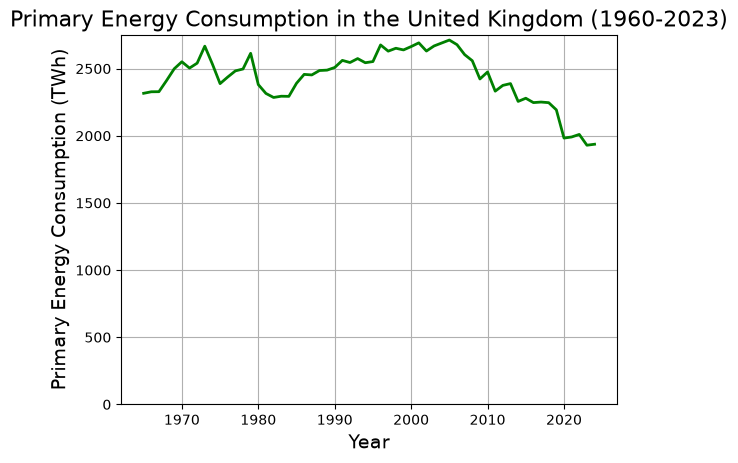

In [14]:
uk_primary_energy_consumption = united_kingdom['primary_energy_consumption']

plt.Figure(figsize=(10, 6))
plt.plot(uk_years, uk_primary_energy_consumption, color='green', linestyle='-', linewidth=2, markersize=6)
plt.title('Primary Energy Consumption in the United Kingdom (1960-2023)', fontsize=16)
plt.xlabel('Year', fontsize=14)
plt.ylabel('Primary Energy Consumption (TWh)', fontsize=14)
plt.ylim(bottom=0)
plt.grid(True)

## Total GHG-emissions (1850-2022)

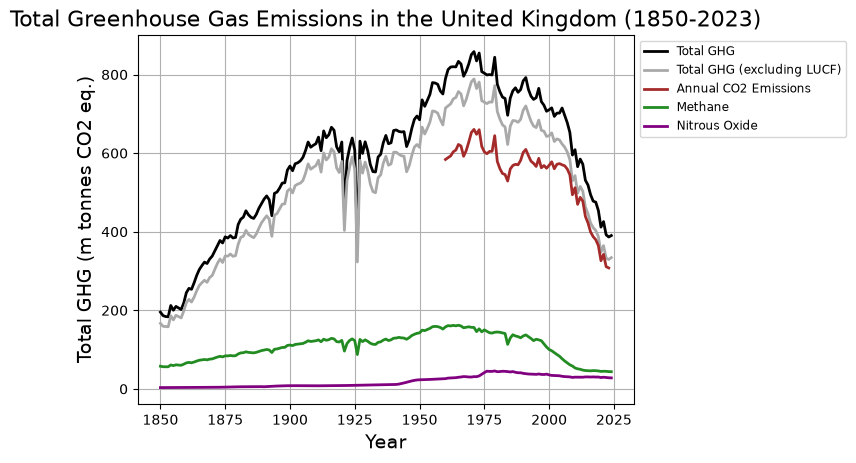

In [15]:
ghg_total = united_kingdom['total_ghg']
total_ghg_excluding_lucf = united_kingdom['total_ghg_excluding_lucf']
methane = united_kingdom['methane']
nitrous_oxide = united_kingdom['nitrous_oxide']

plt.Figure(figsize=(10, 6))
plt.plot(uk_years, ghg_total, color='black', linestyle='-', linewidth=2, markersize=6, label='Total GHG')
plt.plot(uk_years, total_ghg_excluding_lucf, color='darkgrey', linestyle='-', linewidth=2, markersize=6, label='Total GHG (excluding LUCF)')
plt.plot(uk_years[210:-1], annual_co2_emissions[210:-1], color='brown', linestyle='-', linewidth=2, label = 'Annual CO2 Emissions')
plt.plot(uk_years, methane, color='forestgreen', linestyle='-', linewidth=2, markersize=6, label='Methane')
plt.plot(uk_years, nitrous_oxide, color='purple', linestyle='-', linewidth=2, markersize=6, label='Nitrous Oxide')
plt.title('Total Greenhouse Gas Emissions in the United Kingdom (1850-2023)', fontsize=16)
plt.xlabel('Year', fontsize=14)
plt.ylabel('Total GHG (m tonnes CO2 eq.)', fontsize=14)
plt.grid(True) 
plt.legend(fontsize='small', loc='upper left', bbox_to_anchor=(1, 1))

## Per capita emissions

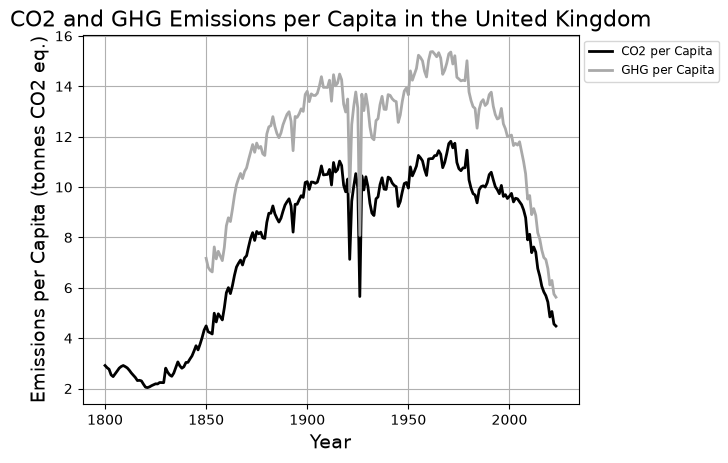

In [16]:
co2_per_capita = united_kingdom['co2_per_capita']
ghg_per_capita = united_kingdom['ghg_per_capita']

plt.Figure(figsize=(10, 6))
plt.plot(uk_years[50:-1], co2_per_capita[50:-1], color='black', linestyle='-', linewidth=2, markersize=6, label='CO2 per Capita')
plt.plot(uk_years[50:-1], ghg_per_capita[50:-1], color='darkgrey', linestyle='-', linewidth=2, markersize=6, label='GHG per Capita')
plt.title('CO2 and GHG Emissions per Capita in the United Kingdom', fontsize=16)
plt.xlabel('Year', fontsize=14)
plt.ylabel('Emissions per Capita (tonnes CO2 eq.)', fontsize=14)
plt.grid(True)
plt.legend(fontsize='small', loc='upper left', bbox_to_anchor=(1, 1))

# Poland

In [17]:
poland = df[df['country'] == 'Poland']
poland_years = poland['year']

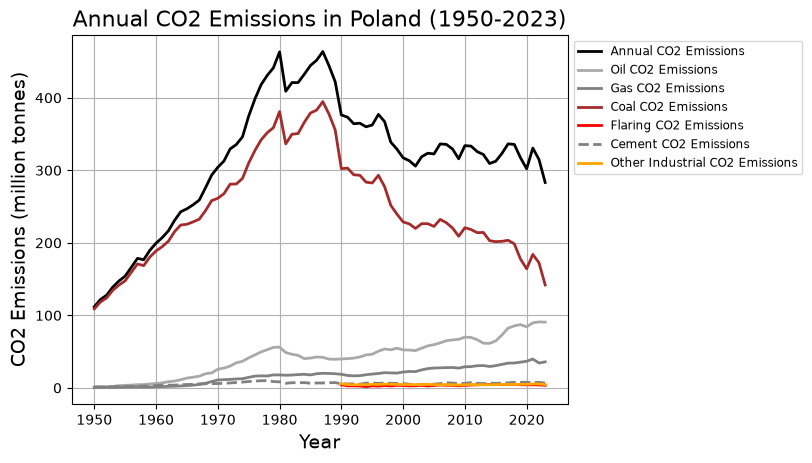

In [18]:
annual_co2_emissions = poland['co2']
cement_co2 = poland['cement_co2']
gas_co2 = poland['gas_co2']
flaring_co2 = poland['flaring_co2']
coal_co2 = poland['coal_co2']
oil_co2 = poland['oil_co2']
other_industrial_co2 = poland['other_industry_co2']

plt.Figure(figsize=(10, 6))

plt.plot(poland_years[150:-1], annual_co2_emissions[150:-1], color='black', linestyle='-', linewidth=2, label = 'Annual CO2 Emissions')
plt.plot(poland_years[150:-1], oil_co2[150:-1], color='darkgrey', linestyle='-', linewidth=2, label = 'Oil CO2 Emissions')
plt.plot(poland_years[150:-1], gas_co2[150:-1], color='grey', linestyle='-', linewidth=2, label = 'Gas CO2 Emissions')
plt.plot(poland_years[150:-1], coal_co2[150:-1], color='brown', linestyle='-', linewidth=2, label = 'Coal CO2 Emissions')
plt.plot(poland_years[150:-1], flaring_co2[150:-1], color='red', linestyle='-', linewidth=2, label = 'Flaring CO2 Emissions')
plt.plot(poland_years[150:-1], cement_co2[150:-1], color='gray', linestyle='--', linewidth=2, label = 'Cement CO2 Emissions')
plt.plot(poland_years[150:-1], other_industrial_co2[150:-1], color='orange', linestyle='-', linewidth=2, label = 'Other Industrial CO2 Emissions')

plt.title('Annual CO2 Emissions in Poland (1950-2023)', fontsize=16)
plt.xlabel('Year', fontsize=14)
plt.ylabel('CO2 Emissions (million tonnes)', fontsize=14)
plt.grid(True)
plt.legend(fontsize='small', loc='upper left', bbox_to_anchor=(1, 1))

## Per capita emissions

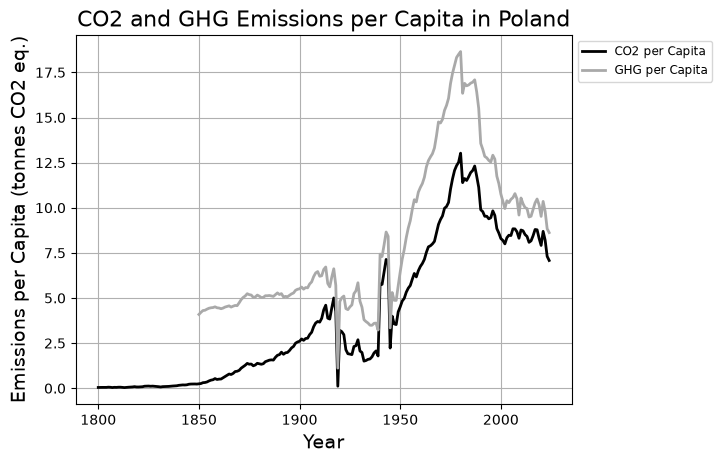

In [19]:
co2_per_capita = poland['co2_per_capita']
ghg_per_capita = poland['ghg_per_capita']

plt.Figure(figsize=(10, 6))
plt.plot(poland_years, co2_per_capita, color='black', linestyle='-', linewidth=2, markersize=6, label='CO2 per Capita')
plt.plot(poland_years, ghg_per_capita, color='darkgrey', linestyle='-', linewidth=2, markersize=6, label='GHG per Capita')
plt.title('CO2 and GHG Emissions per Capita in Poland', fontsize=16)
plt.xlabel('Year', fontsize=14)
plt.ylabel('Emissions per Capita (tonnes CO2 eq.)', fontsize=14)
plt.grid(True)
plt.ylim
plt.legend(fontsize='small', loc='upper left', bbox_to_anchor=(1, 1))

# Germany

In [20]:
germany = df[df['country'] == 'Germany']

In [21]:
order = ['coal', 'oil', 'gas', 'other industry', 'cement', 'flaring']

fig = px.area(
    germany.iloc[50:-1],
    x='year',
    y=[
        'coal_co2',
        'oil_co2',
        'gas_co2',
        'other_industry_co2',
        'cement_co2',
        'flaring_co2'
    ],
    title='CO2 Emissions by Source in Germany',
    labels={
        'value': 'CO2 Emission (tonn)',
        'variable': 'Source',
        'year': 'Year'
    },
    color_discrete_map={
        'coal_co2': "#6D6868",
        'oil_co2': '#8C564B',
        'gas_co2': "#FF9500",
        'other_industry_co2': "#6DC86D",
        'cement_co2': "#BC9753",
        'flaring_co2': '#E45756'
    }
)

fig.for_each_trace(lambda t: t.update(
    name=t.name.replace('_co2', '').replace('_', ' ').capitalize()
))

# Reverser legend-rekkefølgen visuelt
fig.update_layout(
    legend=dict(
        traceorder='reversed'
    )
)

fig.show()

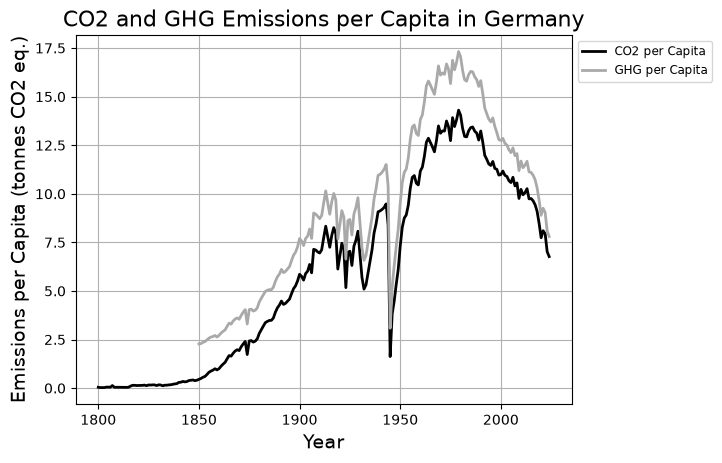

In [22]:
co2_per_capita = germany['co2_per_capita']
ghg_per_capita = germany['ghg_per_capita']

plt.Figure(figsize=(10, 6))
plt.plot(germany.year, co2_per_capita, color='black', linestyle='-', linewidth=2, markersize=6, label='CO2 per Capita')
plt.plot(germany.year, ghg_per_capita, color='darkgrey', linestyle='-', linewidth=2, markersize=6, label='GHG per Capita')
plt.title('CO2 and GHG Emissions per Capita in Germany', fontsize=16)
plt.xlabel('Year', fontsize=14)
plt.ylabel('Emissions per Capita (tonnes CO2 eq.)', fontsize=14)
plt.grid(True)
plt.ylim
plt.legend(fontsize='small', loc='upper left', bbox_to_anchor=(1, 1))

# United States

In [24]:
us = df[df['country'] == 'United States']

In [29]:
order = ['coal', 'oil', 'gas', 'other industry', 'cement', 'flaring']

fig = px.area(
    us.iloc[50:-1],
    x='year',
    y=[
        'coal_co2',
        'oil_co2',
        'gas_co2',
        'other_industry_co2',
        'cement_co2',
        'flaring_co2'
    ],
    title='CO2 Emissions by Source in the US',
    labels={
        'value': 'CO2 Emission (tonn)',
        'variable': 'Source',
        'year': 'Year'
    },
    color_discrete_map={
        'coal_co2': "#735353",
        'oil_co2': "#525252",
        'gas_co2': "#FF9500",
        'other_industry_co2': "#6DC86D",
        'cement_co2': "#BC9753",
        'flaring_co2': '#E45756'
    }
)

fig.for_each_trace(lambda t: t.update(
    name=t.name.replace('_co2', '').replace('_', ' ').capitalize()
))

# Reverser legend-rekkefølgen visuelt
fig.update_layout(
    legend=dict(
        traceorder='reversed'
    )
)

fig.show()

## Per Capita Emissions

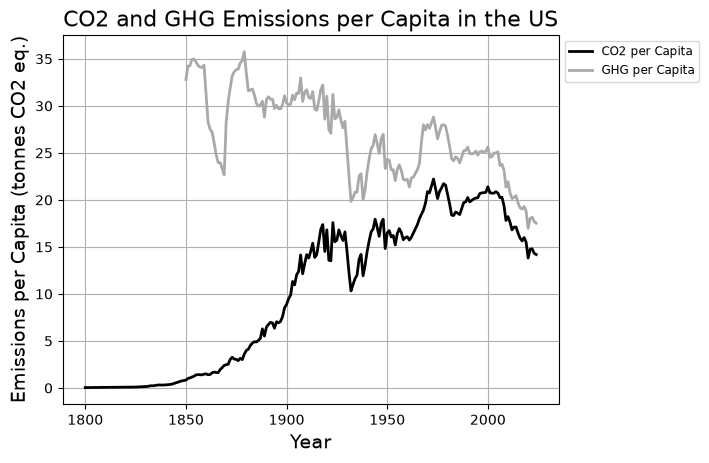

In [30]:
plt.Figure(figsize=(10, 6))
plt.plot(us.year, us.co2_per_capita, color='black', linestyle='-', linewidth=2, markersize=6, label='CO2 per Capita')
plt.plot(us.year, us.ghg_per_capita, color='darkgrey', linestyle='-', linewidth=2, markersize=6, label='GHG per Capita')
plt.title('CO2 and GHG Emissions per Capita in the US', fontsize=16)
plt.xlabel('Year', fontsize=14)
plt.ylabel('Emissions per Capita (tonnes CO2 eq.)', fontsize=14)
plt.grid(True)
plt.ylim
plt.legend(fontsize='small', loc='upper left', bbox_to_anchor=(1, 1))